# H2: płeć i wiek a prawy swipe

## O co pytamy (po ludzku)

W aplikacji osoba **A** widzi profil osoby **B** i przesuwa go w prawo (zainteresowana) albo w lewo
(nie). H2 pyta: **czy płeć i wiek A oraz B wiążą się z tym, czy A przesunie w prawo?**

Chcemy odpowiedzieć liczbami z przedziałem niepewności, a nie samymi procentami. Główna miara to
**iloraz szans (OR)**:

| OR | znaczenie |
|---|---|
| 1 | cecha odbiorcy nic nie zmienia |
| 2 | szansa na prawy swipe jest ok. 2 razy większa |
| 0,5 | szansa jest ok. 2 razy mniejsza |

**Szansa to nie prawdopodobieństwo.** Gdy rzadko swipe'uje się w prawo (tu ok. 21%), OR 2 daje mniej
niż dwukrotnie większe prawdopodobieństwo. Dlatego obok OR podajemy punkty procentowe (p.p.).

## Status: eksploracyjny

Macierz płci (kto swipe'uje kogo) widzieliśmy w EDA, **zanim** napisaliśmy H2 (D17). Wynik oznacza
„zaobserwowaliśmy związek", a nie „potwierdziliśmy hipotezę". Zmiany z audytu (listopad 2026) są
oznaczone jako *pre-rejestrowane* albo *post hoc (audyt)* w `docs/h2/audit-fixes-2026-11-10.md`.

## Jednostka i zmienna wynikowa

Jeden wiersz to jeden swipe A→B na profil. Zmienna wynikowa to `y_right` (1 = prawy, 0 = lewy).
Wszystko poniżej opisuje zachowanie **uwarunkowane ekspozycją**: widzimy tylko profile, które feed
pokazał (G1), a jego reguł nie znamy.

## Decyzje zespołu zastosowane tutaj

(`docs/prompts/m1-generation-plan.md`)
- cechy osoby bierzemy z wersji profilu **z dnia swipe'a**, z flagą źródła (D7),
- konta z miastem Hyderabad wyrzucamy (D10),
- płeć `O` to osobna kategoria w macierzy (D8) i **poza modelami głównymi** (G16); pasma wieku 27+
  łączymy w jedno (D9),
- w analizie głównej **nie** wykluczamy kont skrajnych ani mało aktywnych (D6),
- bez progu „bliskie zeru" i bez modelu dwuetapowego (D17).

## Dwa estymatory i które OR są które (D18, Z3)

- **Populacyjny (pooled):** zwykła regresja logistyczna z błędami standardowymi klastrowanymi po
  nadawcy i odbiorcy. OR opisuje „przeciętną parę".
- **Warunkowy (GLMM):** model z losowymi wyrazami wolnymi nadawcy i odbiorcy. OR opisuje „tę samą
  parę nadawca-odbiorca". Nadawcy bardzo różnią się chęcią swipe'owania (wariancja efektu nadawcy
  ok. 7,9), więc OR warunkowe są **znacznie dalej od 1** niż populacyjne. **Nie porównujemy OR z
  różnych estymatorów bez tego zastrzeżenia**, a przy każdym OR podajemy, który to estymator.
- Błędy standardowe GLMM: gdy GPBoost zbiega, ale nie zwraca SE (D-H3a-26), dopasowujemy model w `lme4` (R, `glmer`, nAGQ = 0). Źródło jest podane przy każdym wyniku.

## Prywatność

Używamy tylko `sex`, `age_band`, `city` i pól swipe'ów. Pole `bio` nie jest wczytywane ani pokazywane.
Do raportu idą tylko liczby zbiorcze; komórki z mniej niż 5 nadawcami są ukryte (`data/README.md`, G12).

## Cache i wykresy

Ciężkie obliczenia (GLMM, bootstrap, walidacja) są w `data/interim/h2/` (poza gitem), a wykresy
tylko je czytają z `rentfriends.h2_figs`. Żeby zmienić styl wykresów, edytuj `h2_figs.STYLE` albo
funkcje rysujące i uruchom komórki wykresów. Nic się nie przelicza. Po zmianie kodu analiz podnieś
`CODE_VERSION` w `h2_cache.py` albo wywołaj `cache.clear()`.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rentfriends import h2, h2_audit, h2_figs
from rentfriends.h2_cache import Cache
from rentfriends.synthetic import make_synthetic_tables

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

SEED = 20261102  # fixed for bootstrap, permutations and CV folds
N_BOOT = 1000  # bootstrap / permutation replicates
DATA_DIR = Path("../data/processed")
REQUIRED = ["users", "swipes", "profile_history"]
H1_V1 = DATA_DIR / "h1_analysis_dataset_v1.parquet"  # read only, for the age bridge to H1

## 1. Wczytanie danych

In [2]:
USE_REAL = all((DATA_DIR / f"{t}.parquet").exists() for t in REQUIRED)
if USE_REAL:
    tables = h2.load_tables(DATA_DIR)
    CACHE = Cache("../data/interim/h2")
    print("PRAWDZIWE DANE z", DATA_DIR.resolve())
else:
    import tempfile

    tables, truth = make_synthetic_tables(n_users=1500, swipes_per_user=60, seed=SEED % 1000)
    CACHE = Cache(tempfile.mkdtemp(prefix="h2_synthetic_"))
    print("!" * 70)
    print("DANE SYNTETYCZNE: nie znaleziono prawdziwych danych.")
    print("Liczby poniżej tylko testują kod i nic nie mówią o RentFriends.")
    print("!" * 70)

print(
    f"użytkownicy: {len(tables.users)}, swipe'y: {len(tables.swipes)}, "
    f"wersje profili: {len(tables.profile_history)}"
)

PRAWDZIWE DANE z /home/dominik/projects/wust/sem2/umc/data/processed
użytkownicy: 2065, swipe'y: 116414, wersje profili: 4508


## 2. Tabela do analizy i filtry

**Co tu się dzieje:** z surowych swipe'ów zostawiamy tylko swipe'y na profile (bez swipe'ów na ogłoszenia
mieszkań i bez swipe'ów na samego siebie), wyrzucamy konta z Hyderabadu i każdemu swipe'owi
przypisujemy płeć i wiek nadawcy oraz odbiorcy **z dnia swipe'a**.

Poniższy lejek pokazuje, ile swipe'ów tracimy na każdym kroku (G6, G7, G10).

In [3]:
df = h2.build_swipe_table(tables)  # main: as-of features (D7), no Hyderabad (D10)

raw = tables.swipes
profile = raw[(raw["target_type"] == "profile") & raw["target_user_key"].notna()]
profile = profile[profile["user_key"] != profile["target_user_key"]]
funnel = pd.Series(
    {
        "wszystkie swipe'y": len(raw),
        "swipe'y na profile (bez swipe'ów na siebie)": len(profile),
        "po wyrzuceniu Hyderabadu (D10)": len(df),
        "znana płeć obu stron": int(df["same_sex"].notna().sum()),
        "...i znane pasmo wieku obu stron": int(df["same_band"].notna().sum()),
        "...płeć F lub M po obu stronach (model Z1, bez O)": int(
            (df["sender_sex"].isin(["F", "M"]) & df["receiver_sex"].isin(["F", "M"])).sum()
        ),
    },
    name="swipe'y",
)
display(funnel.to_frame())

print(
    f"nadawcy: {df['sender'].nunique()}, odbiorcy: {df['receiver'].nunique()}, "
    f"ogólny odsetek prawych swipe'ów = {df['y_right'].mean():.3f}"
)
print()
print("Skąd pochodzi wersja profilu (D7, na poziomie pary):")
display(df["asof_source"].value_counts(normalize=True).to_frame("udział"))
print(
    f"Konta skrajne (same prawe albo same lewe, >= {h2.MIN_SWIPES_ACTIVE} swipe'ów) "
    f"zostają w analizie głównej (D6): {df.loc[df['sender_extreme'], 'sender'].nunique()} kont, "
    f"{int(df['sender_extreme'].sum())} swipe'ów"
)

,swipe'y
wszystkie swipe'y,116414
swipe'y na profile (bez swipe'ów na siebie),95144
po wyrzuceniu Hyderabadu (D10),94295
znana płeć obu stron,94295
...i znane pasmo wieku obu stron,93717
"...płeć F lub M po obu stronach (model Z1, bez O)",91598


nadawcy: 1544, odbiorcy: 1363, ogólny odsetek prawych swipe'ów = 0.205

Skąd pochodzi wersja profilu (D7, na poziomie pary):


,udział
asof_source,
prior_version,0.503
first_version,0.489
users_current,0.008


Konta skrajne (same prawe albo same lewe, >= 10 swipe'ów) zostają w analizie głównej (D6): 347 kont, 15968 swipe'ów


## 2a. Obliczenia (z cache)

**Co tu się dzieje:** jedna komórka liczy (albo wczytuje z `data/interim/h2/`) wszystko, co jest
niżej: macierze, modele GLMM i pooled, walidację. Pierwszy przebieg trwa kilkanaście minut (głównie
`lme4`), kolejne są natychmiastowe. Wynikiem jest słownik `R` z samymi agregatami.

In [4]:
h1_df = pd.read_parquet(H1_V1) if H1_V1.exists() else None
R = h2_audit.run_all(df, h1_df, CACHE, tables=tables, n_boot=N_BOOT, seed=SEED)
print(R["sizes"])

or_crude: cache
or_adjusted: cache
perm: cache
sensitivity: cache
old_cv: cache
z1_matrix: cache
z1_fit_bare: cache
z1_fe_bare: cache
z1_fit_controls: cache
z1_fe_controls: cache
z2_matrix: cache
z2_models: cache
z2_bridge: cache
z4_oof_sender: cache
z4_cv_sender: cache
z4_oof_receiver: cache
z4_cv_receiver: cache
{'rows': 94295, 'z1_bare': 91598, 'z1_controls': 91121, 'age': 93717}


## 2a. Obliczenia (z cache)

**Co tu się dzieje:** jedna komórka liczy (albo wczytuje z `data/interim/h2/`) wszystko, co jest
niżej: macierze, modele GLMM i pooled, walidację. Pierwszy przebieg trwa kilkanaście minut (głównie
`lme4`), kolejne są natychmiastowe. Wynikiem jest słownik `R` z samymi agregatami.

,n swipe'ów,n prawych,odsetek prawych,przedział (bootstrap po nadawcach)
komórka (nadawca -> odbiorca),,,,
F -> F,32101,6435,0.200,"[0.174, 0.230]"
F -> M,17242,1469,0.085,"[0.062, 0.111]"
F -> O,958,107,0.112,"[0.085, 0.141]"
M -> F,24857,7358,0.296,"[0.248, 0.345]"
M -> M,17398,3467,0.199,"[0.162, 0.240]"
M -> O,840,157,0.187,"[0.145, 0.231]"
O -> F,533,210,0.394,"[0.214, 0.581]"
O -> M,345,151,0.438,"[0.134, 0.659]"
O -> O,21,9,0.429,"[0.118, 0.731]"


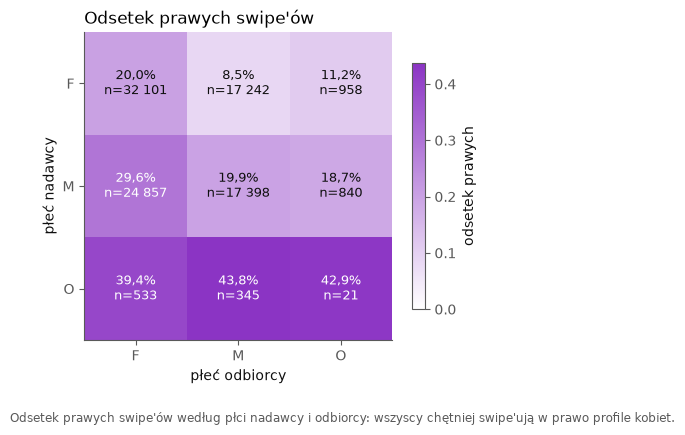

In [5]:
matrix = R["z1_matrix"]
tbl = matrix.assign(
    cell=lambda t: t["sender_sex"] + " -> " + t["receiver_sex"],
    ci=lambda t: t.apply(
        lambda r: "" if pd.isna(r["rate"]) else f"[{r['ci_low']:.3f}, {r['ci_high']:.3f}]", axis=1
    ),
)[["cell", "n", "k", "rate", "ci"]]
tbl.columns = [
    "komórka (nadawca -> odbiorca)",
    "n swipe'ów",
    "n prawych",
    "odsetek prawych",
    "przedział (bootstrap po nadawcach)",
]
display(tbl.set_index("komórka (nadawca -> odbiorca)"))
fig = h2_figs.sex_matrix(R)
plt.show()

## 2a. Obliczenia (z cache)

**Co tu się dzieje:** jedna komórka liczy (albo wczytuje z `data/interim/h2/`) wszystko, co jest
niżej: macierze, modele GLMM i pooled, walidację. Pierwszy przebieg trwa kilkanaście minut (głównie
`lme4`), kolejne są natychmiastowe. Wynikiem jest słownik `R` z samymi agregatami.

,z kontrolami,płeć nadawcy,n swipe'ów,n nadawców,P(prawy | ta sama płeć),P(prawy | inna płeć),OR (pooled),OR dół 95%,OR góra 95%,p
0,False,F,50301,871,0.200,0.087,2.645,2.063,3.390,0.000
1,False,M,43095,664,0.199,0.292,0.602,0.498,0.729,0.000
2,False,O,899,30,0.429,0.411,1.074,0.490,2.355,0.858
3,True,F,50241,871,0.201,0.087,2.439,1.909,3.116,0.000
4,True,M,42621,659,0.201,0.295,0.657,0.541,0.799,0.000
5,True,O,855,28,0.450,0.414,1.143,0.473,2.759,0.767


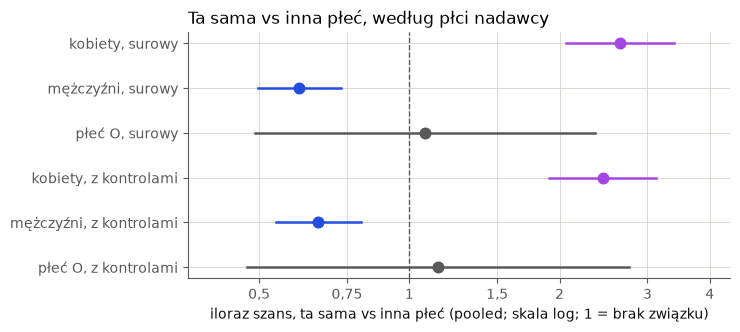

In [6]:
crude, adjusted = R["or_crude"], R["or_adjusted"]
main_res = pd.concat([crude, adjusted], ignore_index=True)
shown = main_res[
    [
        "controls",
        "sender_sex",
        "n",
        "n_senders",
        "p_right_same",
        "p_right_diff",
        "odds_ratio",
        "ci_low",
        "ci_high",
        "p_value",
    ]
].copy()
shown.columns = [
    "z kontrolami",
    "płeć nadawcy",
    "n swipe'ów",
    "n nadawców",
    "P(prawy | ta sama płeć)",
    "P(prawy | inna płeć)",
    "OR (pooled)",
    "OR dół 95%",
    "OR góra 95%",
    "p",
]
display(shown)

SEX_PL = {"F": "kobiety", "M": "mężczyźni", "O": "płeć O"}
colors = {"F": h2_figs.STYLE["purple"], "M": h2_figs.STYLE["blue"], "O": h2_figs.STYLE["gray"]}
h2_figs._apply()
plot = main_res.assign(
    label=lambda t: (
        t["sender_sex"].map(SEX_PL) + ", " + np.where(t["controls"], "z kontrolami", "surowy")
    )
).sort_values(["controls", "sender_sex"])
fig, ax = plt.subplots(figsize=(7, 3.2))
for y, (_, r) in enumerate(plot.iterrows()):
    h2_figs._dot(ax, y, r["odds_ratio"], r["ci_low"], r["ci_high"], colors[r["sender_sex"]])
ax.set_yticks(range(len(plot)), plot["label"])
ax.invert_yaxis()
h2_figs._or_axis(ax, 0.4, 4)
ax.set_xlabel("iloraz szans, ta sama vs inna płeć (pooled; skala log; 1 = brak związku)")
ax.set_title("Ta sama vs inna płeć, według płci nadawcy", loc="left")
plt.show()

## 3. Macierz: jaki odsetek swipe'ów jest prawy, według płci nadawcy i odbiorcy

**Jak czytać:** wiersz to płeć nadawcy, kolumna to płeć odbiorcy. Komórka `F → M` to odsetek prawych
swipe'ów, które **kobiety** dały **mężczyznom**. Jeśli ludzie wolą swoją płeć, przekątna (`F → F`,
`M → M`) będzie ciemniejsza niż reszta.

Przedziały ufności w tabeli (`ci`) liczymy przez **bootstrap po nadawcach**: losujemy całych ludzi, a nie
pojedyncze swipe'y. Są szersze niż przedział Wilsona z EDA, który zakładał, że każdy swipe jest niezależny.

Płeć `O` jest rzadka i najczęściej powstaje przez zmianę płci w profilu (G16), więc te komórki czytamy
ostrożnie. Tę macierz widzieliśmy przed H2, dlatego jest eksploracyjna.

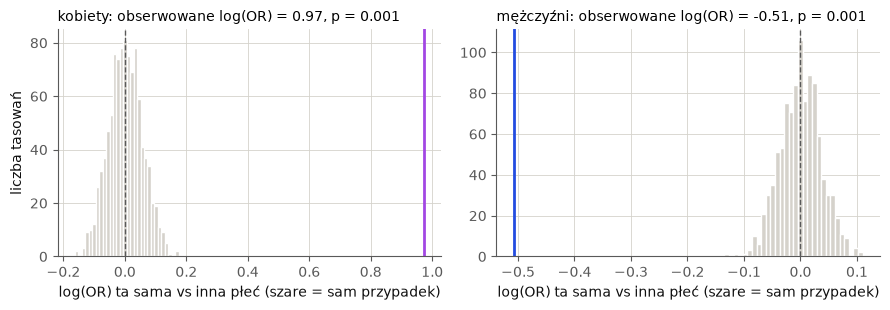

,obserwowane log(OR),"przypadek 2,5%","przypadek 97,5%",p_perm
płeć nadawcy,,,,
F,0.972,-0.103,0.109,0.001
M,-0.507,-0.066,0.070,0.001


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
perm_rows = []
for ax, g, col in zip(
    axes, ["F", "M"], [h2_figs.STYLE["purple"], h2_figs.STYLE["blue"]], strict=True
):
    obs, null = R["perm"][g]
    p = (np.sum(np.abs(null) >= abs(obs)) + 1) / (len(null) + 1)
    lo, hi = np.quantile(null, [0.025, 0.975])
    perm_rows.append(
        {
            "płeć nadawcy": g,
            "obserwowane log(OR)": obs,
            "przypadek 2,5%": lo,
            "przypadek 97,5%": hi,
            "p_perm": p,
        }
    )
    ax.hist(null, bins=30, color=h2_figs.STYLE["hair"], edgecolor="white")
    ax.axvline(obs, color=col, lw=2)
    ax.axvline(0, color=h2_figs.STYLE["gray"], ls="--", lw=1)
    ax.set_title(
        f"{SEX_PL[g]}: obserwowane log(OR) = {obs:.2f}, p = {p:.3f}", loc="left", fontsize=10
    )
    ax.set_xlabel("log(OR) ta sama vs inna płeć (szare = sam przypadek)")
axes[0].set_ylabel("liczba tasowań")
plt.tight_layout()
plt.show()
display(pd.DataFrame(perm_rows).set_index("płeć nadawcy"))

### 4.1 Popularność profili czy premia za własną płeć? (Z1)

Powyższe OR mieszają dwie rzeczy: (i) profile kobiet mogą dostawać więcej prawych swipe'ów od wszystkich,
(ii) ludzie mogą mieć premię za własną płeć. Czy z tych danych da się je rozdzielić?

**Co jest zidentyfikowane.** W tabeli 2×2 (nadawca F/M × odbiorca F/M), z efektami nadawcy i odbiorcy,
istnieją dwie różnice „odbiorca F vs M": jedna dla nadawców F (luka `gap_F`) i jedna dla nadawców M
(`gap_M`). **Identyfikowany jest jeden kontrast interakcyjny** `2h = gap_F − gap_M`
(`sender_F × receiver_F`), a nie osobne premie za własną płeć dla kobiet i mężczyzn. Osobnych
`h_F`, `h_M` nie raportujemy.

**Założenie identyfikacyjne (potrzebne do rozdzielenia).** Popularność profili kobiet `π` jest taka sama
dla obu płci nadawców i premia za własną płeć `h` jest taka sama dla obu płci nadawców. Wtedy
`gap_F = π + h`, `gap_M = π − h`, więc `h = (gap_F + gap_M)/2 … ` w skali log-OR z odwróceniem znaku
dla mężczyzn, czyli `π` = współczynnik `receiver_F`, a `h` = współczynnik `sender_F × receiver_F`
(kodowanie nadawcy +1 dla kobiet, −1 dla mężczyzn). Jeśli założenie jest fałszywe (np. mężczyźni
inaczej oceniają popularność kobiet niż kobiety), `π` i `h` nie mają tej interpretacji. Zidentyfikowane
bez założeń zostają tylko `gap_F`, `gap_M` i ich iloraz `exp(2h)`.

`receiver_F` jest cechą odbiorcy skorelowaną z innymi cechami (wiek, miasto, sposób prowadzenia
profilu), więc „popularność profili kobiet" to nazwa zbiorcza, nie efekt samej płci. Płeć `O` jest
poza modelem (G16). Wnioski dotyczą zachowania uwarunkowanego ekspozycją (G1): korelacja, nie preferencja.

In [8]:
sizes = R["sizes"]
print(
    f"próba Z1 bez kontroli: {sizes['z1_bare']} swipe'ów, z kontrolami (wiek, miasto): {sizes['z1_controls']}"  # noqa: E501
)
for tag, title in (("bare", "bez kontroli"), ("controls", "z kontrolami (wiek, miasto)")):
    d = R[f"z1_derived_{tag}"].copy()
    fit = R[f"z1_fit_{tag}"]
    src = fit["pm"].get("glmm_source")
    print(
        f"\n{title}: n = {fit['n']}, nadawców {fit['n_senders']}, odbiorców {fit['n_receivers']}; źródło GLMM: {src}"  # noqa: E501
    )
    d["OR [95% CI]"] = d.apply(
        lambda r: f"{r['or']:.2f} [{r['or_lo']:.2f}; {r['or_hi']:.2f}]", axis=1
    )
    display(
        d[["estimator", "quantity", "log_or", "se", "OR [95% CI]"]].set_index(
            ["estimator", "quantity"]
        )
    )
    g = fit["pm"].get("glmm")
    if fit["pm"]["glmm_ok"]:
        print(f"wariancja efektu nadawcy {g['var_sender']:.2f}, odbiorcy {g['var_receiver']:.2f}")

próba Z1 bez kontroli: 91598 swipe'ów, z kontrolami (wiek, miasto): 91121

bez kontroli: n = 91598, nadawców 1529, odbiorców 1343; źródło GLMM: lme4 (glmer, nAGQ=0)


log_or    se        OR [95% CI]
estimator            quantity                                                                   
pooled (populacyjne) pi: popularność profili F (przy symetrii)    0.757 0.084  2.13 [1.81; 2.51]
                     h: premia za własną płeć (przy symetrii)     0.233 0.080  1.26 [1.08; 1.48]
                     gap_F: odbiorca F vs M, nadawcy F            0.990 0.131  2.69 [2.08; 3.48]
                     gap_M: odbiorca F vs M, nadawcy M            0.524 0.099  1.69 [1.39; 2.05]
                     or_same_M: ta sama vs inna płeć, nadawcy M  -0.524 0.099  0.59 [0.49; 0.72]
                     ratio_of_gaps = 2h (bez założeń)             0.466 0.160  1.59 [1.16; 2.18]
GLMM (warunkowe)     pi: popularność profili F (przy symetrii)    1.362 0.060  3.91 [3.47; 4.39]
                     h: premia za własną płeć (przy symetrii)     0.329 0.028  1.39 [1.32; 1.47]
                     gap_F: odbiorca F vs M, nadawcy F            1.692 0.069  5.43 [4.75; 6.21]
                     gap_M: odbiorca F vs M, nadawcy M            1.033 0.064  2.81 [2.48; 3.18]
                     or_same_M: ta sama vs inna płeć, nadawcy M  -1.033 0.064  0.36 [0.31; 0.40]
                     ratio_of_gaps = 2h (bez założeń)             0.659 0.056  1.93 [1.73; 2.16]

wariancja efektu nadawcy 7.53, odbiorcy 0.70

z kontrolami (wiek, miasto): n = 91121, nadawców 1524, odbiorców 1340; źródło GLMM: GPBoost


log_or    se        OR [95% CI]
estimator            quantity                                                                   
pooled (populacyjne) pi: popularność profili F (przy symetrii)    0.649 0.082  1.91 [1.63; 2.25]
                     h: premia za własną płeć (przy symetrii)     0.227 0.081  1.25 [1.07; 1.47]
                     gap_F: odbiorca F vs M, nadawcy F            0.876 0.128  2.40 [1.87; 3.09]
                     gap_M: odbiorca F vs M, nadawcy M            0.422 0.100  1.53 [1.25; 1.86]
                     or_same_M: ta sama vs inna płeć, nadawcy M  -0.422 0.100  0.66 [0.54; 0.80]
                     ratio_of_gaps = 2h (bez założeń)             0.454 0.162  1.57 [1.15; 2.17]
GLMM (warunkowe)     pi: popularność profili F (przy symetrii)    1.224 0.052  3.40 [3.07; 3.77]
                     h: premia za własną płeć (przy symetrii)     0.326 0.029  1.39 [1.31; 1.47]
                     gap_F: odbiorca F vs M, nadawcy F            1.550 0.064  4.71 [4.16; 5.34]
                     gap_M: odbiorca F vs M, nadawcy M            0.895 0.058  2.45 [2.19; 2.74]
                     or_same_M: ta sama vs inna płeć, nadawcy M  -0.895 0.058  0.41 [0.36; 0.46]
                     ratio_of_gaps = 2h (bez założeń)             0.652 0.057  1.92 [1.72; 2.15]

wariancja efektu nadawcy 7.86, odbiorcy 0.58


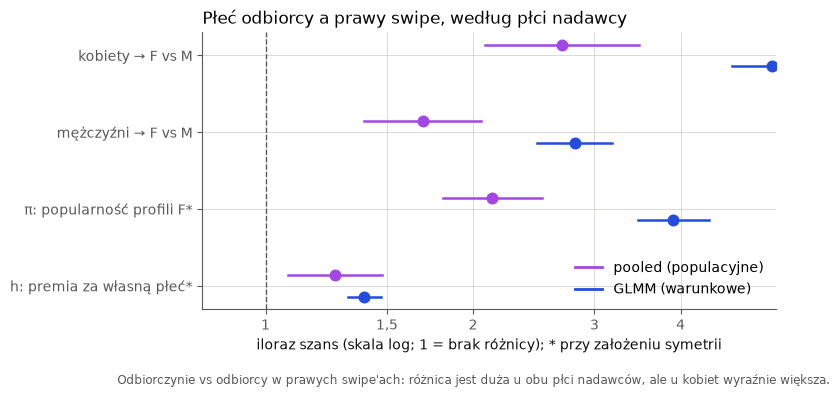

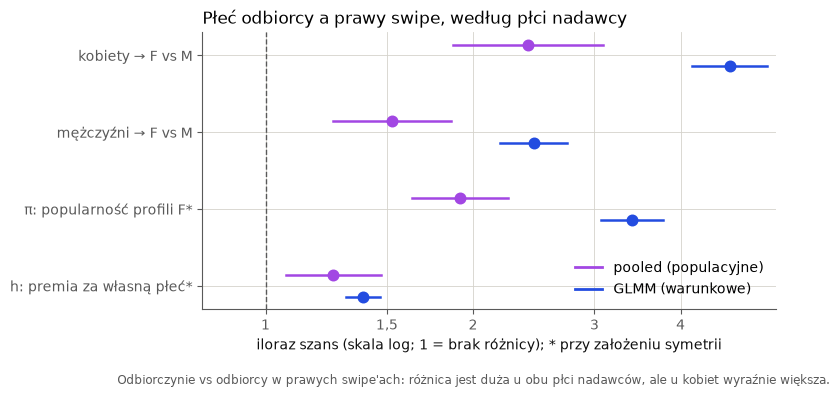

In [9]:
fig = h2_figs.sex_decomposition(R, controls=False)
plt.show()
fig = h2_figs.sex_decomposition(R, controls=True)
plt.show()

**Model z efektami stałymi nadawcy (Z1 b).** Porównujemy, jak *ten sam nadawca* traktuje profile kobiet
i mężczyzn (efekty stałe nadawcy, SE klastrowane po odbiorcy). To najbardziej warunkowe OR ze
wszystkich, bo wyłącza całą różnorodność między nadawcami; pokazujemy je jako kontrolę kierunku, nie
jako główny wynik.

In [10]:
rows = []
for tag, title in (("bare", "bez kontroli"), ("controls", "z kontrolami")):
    for variant, res in R[f"z1_fe_{tag}"].items():
        for nm, b, se in zip(res["names"], res["coef"], res["se"], strict=True):
            if nm.startswith("receiver_F") or nm.startswith("sender_F"):
                rows.append(
                    {
                        "model": title,
                        "wariant": variant,
                        "składnik": nm,
                        "log-OR": b,
                        "SE": se,
                        "OR [95% CI]": f"{np.exp(b):.2f} [{np.exp(b - 1.96 * se):.2f}; {np.exp(b + 1.96 * se):.2f}]",  # noqa: E501
                        "n": res["n_obs_used"],
                    }
                )
display(pd.DataFrame(rows).set_index(["model", "wariant", "składnik"]))

log-OR    SE        OR [95% CI]      n
model        wariant          składnik                                                   
bez kontroli main_effect      receiver_F            1.159 0.056  3.19 [2.86; 3.55]  74673
             with_interaction receiver_F            1.210 0.058  3.35 [3.00; 3.75]  74673
                              sender_F:receiver_F   0.340 0.033  1.40 [1.32; 1.50]  74673
z kontrolami main_effect      receiver_F            1.023 0.053  2.78 [2.51; 3.09]  74322
             with_interaction receiver_F            1.073 0.055  2.92 [2.63; 3.25]  74322
                              sender_F:receiver_F   0.329 0.033  1.39 [1.30; 1.48]  74322

## 5. Wiek (Z2)

**Pytanie:** czy wiek nadawcy i odbiorcy wiąże się z prawym swipe'em, a jeśli tak, to jak? Używamy
tej samej specyfikacji co w H1: `same_band` (to samo pasmo), `age_band_diff_abs` (odległość w pasmach) i
`age_band_diff` (ze znakiem: pasmo odbiorcy − pasmo nadawcy; dla nadawców 18–20 nie bywa ujemna), plus
te same kontrole (para płci, miasto). Pasma: 18–20, 21–23, 24–26, 27+.

### 5.1 Macierz: odsetek prawych według wieku nadawcy i odbiorcy
Przedziały to bootstrap po nadawcach; komórki z mniej niż 5 nadawcami są ukryte (G12).

n  n_senders      odsetek [95% CI]
sender_band receiver_band                                        
18-20       18-20          39616        892  0.205 [0.179; 0.234]
            21-23          11070        809  0.137 [0.112; 0.164]
            24-26           4630        677  0.095 [0.073; 0.116]
            27+             3137        581  0.066 [0.042; 0.097]
21-23       18-20          12819        303  0.263 [0.207; 0.326]
            21-23           3981        269  0.271 [0.219; 0.328]
            24-26           1767        250  0.205 [0.156; 0.256]
            27+             1423        213  0.119 [0.074; 0.171]
24-26       18-20           4925        125  0.301 [0.186; 0.420]
            21-23           1763        125  0.313 [0.205; 0.425]
            24-26            811        115  0.270 [0.180; 0.363]
            27+              716        100  0.175 [0.088; 0.285]
27+         18-20           4118        135  0.242 [0.175; 0.326]
            21-23           1399        135  0.215 [0.155; 0.287]
            24-26            741        124  0.236 [0.168; 0.313]
            27+              801        107  0.253 [0.176; 0.339]

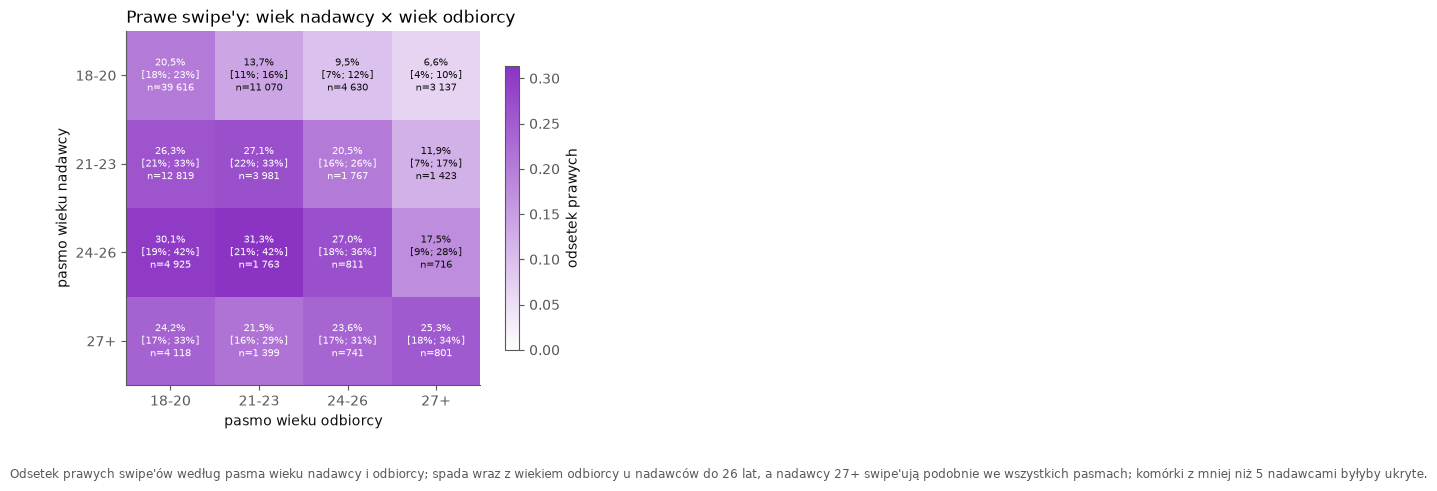

In [11]:
m = R["z2_matrix"].copy()
m["odsetek [95% CI]"] = m.apply(
    lambda r: (
        "ukryte (< 5 nadawców)"
        if r["suppressed"]
        else f"{r['rate']:.3f} [{r['ci_low']:.3f}; {r['ci_high']:.3f}]"
    ),
    axis=1,
)
display(
    m[["sender_band", "receiver_band", "n", "n_senders", "odsetek [95% CI]"]].set_index(
        ["sender_band", "receiver_band"]
    )
)
fig = h2_figs.age_matrix(R)
plt.show()

### 5.2 Model i OR składników

Dwie parametryzacje **tego samego modelu** (ten sam log-likelihood): `linear` (jak w H1: `same_band`,
`age_band_diff_abs`, `age_band_diff`) oraz `dir`, która wprost podaje OR starszego i młodszego odbiorcy
**na jedno pasmo różnicy**. `fe=1` dodaje efekty stałe pasma nadawcy (wrażliwość). Dla każdego OR
podany jest estymator.

coef    se        OR [95% CI]
parametryzacja | FE pasma term              estimator                                           
linear|fe=0               same_band         pooled (populacyjne) -0.259 0.163  0.77 [0.56; 1.06]
                          age_band_diff_abs pooled (populacyjne) -0.300 0.092  0.74 [0.62; 0.89]
                          age_band_diff     pooled (populacyjne) -0.241 0.045  0.79 [0.72; 0.86]
                          same_band         GLMM (warunkowe)      0.001 0.057  1.00 [0.90; 1.12]
                          age_band_diff_abs GLMM (warunkowe)     -0.395 0.034  0.67 [0.63; 0.72]
                          age_band_diff     GLMM (warunkowe)     -0.334 0.029  0.72 [0.68; 0.76]
dir|fe=0                  same_band         pooled (populacyjne) -0.259 0.163  0.77 [0.56; 1.06]
                          older_per_band    pooled (populacyjne) -0.541 0.110  0.58 [0.47; 0.72]
                          younger_per_band  pooled (populacyjne) -0.059 0.094  0.94 [0.78; 1.13]
                          same_band         GLMM (warunkowe)      0.001 0.057  1.00 [0.90; 1.12]
                          older_per_band    GLMM (warunkowe)     -0.729 0.045  0.48 [0.44; 0.53]
                          younger_per_band  GLMM (warunkowe)     -0.061 0.044  0.94 [0.86; 1.03]
linear|fe=1               same_band         pooled (populacyjne)  0.030 0.066  1.03 [0.90; 1.17]
                          age_band_diff_abs pooled (populacyjne) -0.209 0.051  0.81 [0.73; 0.90]
                          age_band_diff     pooled (populacyjne) -0.167 0.030  0.85 [0.80; 0.90]
                          same_band         GLMM (warunkowe)     -0.004 0.057  1.00 [0.89; 1.11]
                          age_band_diff_abs GLMM (warunkowe)     -0.401 0.034  0.67 [0.63; 0.72]
                          age_band_diff     GLMM (warunkowe)     -0.321 0.031  0.73 [0.68; 0.77]
dir|fe=1                  same_band         pooled (populacyjne)  0.030 0.066  1.03 [0.90; 1.17]
                          older_per_band    pooled (populacyjne) -0.377 0.061  0.69 [0.61; 0.77]
                          younger_per_band  pooled (populacyjne) -0.042 0.057  0.96 [0.86; 1.07]
                          same_band         GLMM (warunkowe)     -0.004 0.057  1.00 [0.89; 1.11]
                          older_per_band    GLMM (warunkowe)     -0.722 0.046  0.49 [0.44; 0.53]
                          younger_per_band  GLMM (warunkowe)     -0.080 0.046  0.92 [0.84; 1.01]

n próby wiekowej: 93717 | źródło GLMM: {'linear|fe=0': 'lme4 (glmer, nAGQ=0)', 'dir|fe=0': 'lme4 (glmer, nAGQ=0)', 'linear|fe=1': 'lme4 (glmer, nAGQ=0)', 'dir|fe=1': 'lme4 (glmer, nAGQ=0)'}
log-likelihood (pooled): linear vs dir równe: True True


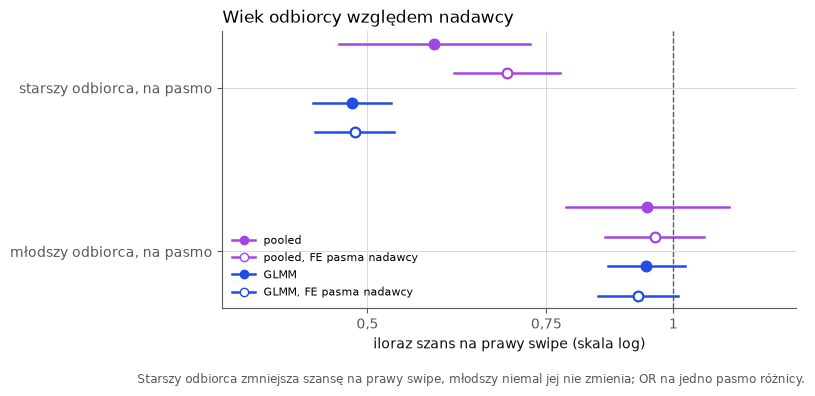

In [12]:
z2 = R["z2_models"]
rows = []
for key, est in z2.items():
    if key == "n":
        continue
    t = h2_audit.term_table(est, key)
    t = t[
        t["term"].isin(
            [
                "same_band",
                "age_band_diff_abs",
                "age_band_diff",
                "older_per_band",
                "younger_per_band",
            ]
        )
    ]
    rows.append(t)
t2 = pd.concat(rows)
t2["OR [95% CI]"] = t2.apply(
    lambda r: (
        f"{r['or']:.2f} [{r['or_lo']:.2f}; {r['or_hi']:.2f}]"
        if np.isfinite(r["or_lo"])
        else f"{r['or']:.2f} (bez SE)"
    ),
    axis=1,
)
t2["parametryzacja | FE pasma"] = t2["model"]
display(
    t2.set_index(["parametryzacja | FE pasma", "term", "estimator"])[["coef", "se", "OR [95% CI]"]]
)
print(
    "n próby wiekowej:",
    z2["n"],
    "| źródło GLMM:",
    {k: v.get("glmm_source") for k, v in z2.items() if k != "n"},
)
ll = {k: (v["pooled"]["loglik"]) for k, v in z2.items() if k != "n"}
print(
    "log-likelihood (pooled): linear vs dir równe:",
    np.isclose(ll["linear|fe=0"], ll["dir|fe=0"], atol=1e-6),
    np.isclose(ll["linear|fe=1"], ll["dir|fe=1"], atol=1e-6),
)
fig = h2_figs.age_or(R)
plt.show()

### 5.3 Spójność z H1: skąd różnice w OR wieku

H1 (v1) podaje OR starszego o 1 pasmo ≈ 0,62 [0,57; 0,68], o 2+ ≈ 0,35 [0,29; 0,43], młodszego o 1 ≈ 0,97
[0,87; 1,09]: model z dummies dla różnicy pasm, efektami stałymi pasma nadawcy, **bez kontroli płci i
miasta**, SE klastrowane po nadawcy, próba 92 754 swipe'ów (wymaga znanego pola stylu życia). Poniżej
zmieniamy jedną rzecz naraz (`age_direction_check` z `rentfriends.h1_audit`, tylko do odczytu).

term,younger_by_2plus,younger_by_1,older_by_1,older_by_2plus
step,,,,
"1. próba H1 (92 754), SE po nadawcy",0.99 [0.81; 1.20],0.97 [0.87; 1.09],0.62 [0.56; 0.68],0.36 [0.29; 0.43]
"2. próba H2 (93 717), SE po nadawcy",1.00 [0.82; 1.21],0.97 [0.87; 1.09],0.62 [0.57; 0.68],0.35 [0.29; 0.43]
3. + klastry nadawca i odbiorca,1.00 [0.80; 1.24],0.97 [0.86; 1.10],0.62 [0.55; 0.70],0.35 [0.29; 0.44]
"4. + kontrole: para płci, miasto",0.87 [0.70; 1.07],0.92 [0.82; 1.04],0.67 [0.59; 0.74],0.41 [0.33; 0.50]


                                     n swipe'ów
step                                           
1. próba H1 (92 754), SE po nadawcy       92754
2. próba H2 (93 717), SE po nadawcy       93717
3. + klastry nadawca i odbiorca           93717
4. + kontrole: para płci, miasto          93717


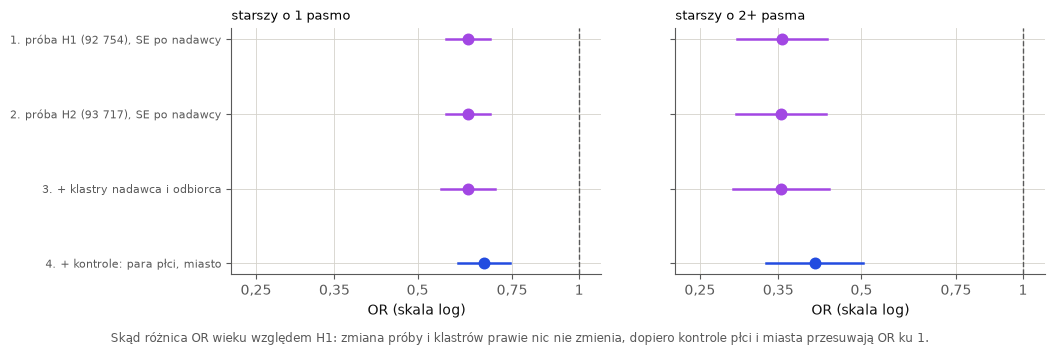

In [13]:
if "z2_bridge" in R:
    b = R["z2_bridge"].copy()
    b["OR [95% CI]"] = b.apply(
        lambda r: f"{r['or']:.2f} [{r['or_lo']:.2f}; {r['or_hi']:.2f}]", axis=1
    )
    display(
        b.pivot(index="step", columns="term", values="OR [95% CI]")[
            ["younger_by_2plus", "younger_by_1", "older_by_1", "older_by_2plus"]
        ]
    )
    print(b.groupby("step")["n"].first().to_frame("n swipe'ów"))
    fig = h2_figs.bridge(R)
    plt.show()
else:
    print("Brak pliku h1_analysis_dataset_v1.parquet: pomijam porównanie z H1.")

## 6. Estymatory, wrażliwość i walidacja

### 6.1 Estymator populacyjny vs warunkowy (Z3)

Tabela obok siebie dla modeli z sekcji 4.1 i 5.2. **Różnica jest duża**, bo efekt nadawcy ma wariancję
ok. 7,9 (SD ok. 2,8 logitu): dla konkretnego nadawcy prawy swipe jest albo prawie pewny, albo prawie
wykluczony, więc OR warunkowe (na tego samego nadawcę i odbiorcę) są dalej od 1 niż OR populacyjne
(uśrednione po ludziach). Nie wolno ich porównywać z OR z innego estymatora bez tego zastrzeżenia.

OR pooled [95% CI]   OR GLMM [95% CI]           źródło GLMM wariancja nadawcy / odbiorcy
model           składnik                                                                                                    
Z1 bez kontroli receiver_F           2.13 [1.81; 2.51]  3.91 [3.47; 4.39]  lme4 (glmer, nAGQ=0)                    7.5 / 0.7
                sender_F:receiver_F  1.26 [1.08; 1.48]  1.39 [1.32; 1.47]  lme4 (glmer, nAGQ=0)                    7.5 / 0.7
Z1 z kontrolami receiver_F           1.91 [1.63; 2.25]  3.40 [3.07; 3.77]               GPBoost                    7.9 / 0.6
                sender_F:receiver_F  1.25 [1.07; 1.47]  1.39 [1.31; 1.47]               GPBoost                    7.9 / 0.6
Z2 linear|fe=0  same_band            0.77 [0.56; 1.06]  1.00 [0.90; 1.12]  lme4 (glmer, nAGQ=0)                    7.5 / 0.6
                age_band_diff_abs    0.74 [0.62; 0.89]  0.67 [0.63; 0.72]  lme4 (glmer, nAGQ=0)                    7.5 / 0.6
                age_band_diff        0.79 [0.72; 0.86]  0.72 [0.68; 0.76]  lme4 (glmer, nAGQ=0)                    7.5 / 0.6
Z2 linear|fe=1  same_band            1.03 [0.90; 1.17]  1.00 [0.89; 1.11]  lme4 (glmer, nAGQ=0)                    7.5 / 0.6
                age_band_diff_abs    0.81 [0.73; 0.90]  0.67 [0.63; 0.72]  lme4 (glmer, nAGQ=0)                    7.5 / 0.6
                age_band_diff        0.85 [0.80; 0.90]  0.73 [0.68; 0.77]  lme4 (glmer, nAGQ=0)                    7.5 / 0.6
Z2 dir|fe=0     older_per_band       0.58 [0.47; 0.72]  0.48 [0.44; 0.53]  lme4 (glmer, nAGQ=0)                    7.5 / 0.6
                younger_per_band     0.94 [0.78; 1.13]  0.94 [0.86; 1.03]  lme4 (glmer, nAGQ=0)                    7.5 / 0.6
Z2 dir|fe=1     older_per_band       0.69 [0.61; 0.77]  0.49 [0.44; 0.53]  lme4 (glmer, nAGQ=0)                    7.5 / 0.6
                younger_per_band     0.96 [0.86; 1.07]  0.92 [0.84; 1.01]  lme4 (glmer, nAGQ=0)                    7.5 / 0.6

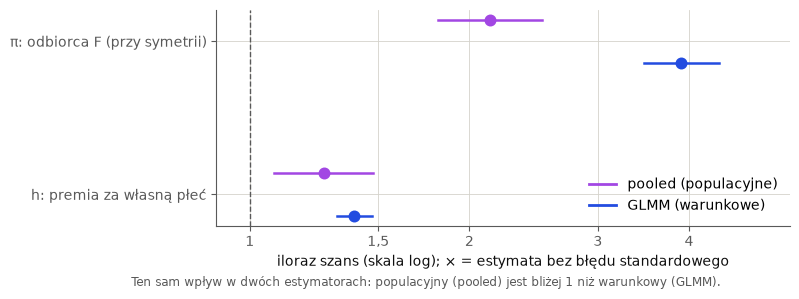

In [14]:
rows = []


def add(model, est, terms):
    t = h2_audit.term_table(est, model, terms)
    for term in terms:
        r = {"model": model, "składnik": term}
        for _, x in t[t["term"] == term].iterrows():
            key = "pooled" if x["estimator"].startswith("pooled") else "GLMM"
            r[f"OR {key} [95% CI]"] = (
                f"{x['or']:.2f} [{x['or_lo']:.2f}; {x['or_hi']:.2f}]"
                if np.isfinite(x["or_lo"])
                else f"{x['or']:.2f} (bez SE)"
            )
        r["źródło GLMM"] = est.get("glmm_source")
        r["wariancja nadawcy / odbiorcy"] = (
            f"{est['glmm']['var_sender']:.1f} / {est['glmm']['var_receiver']:.1f}"
            if est.get("glmm") and "var_sender" in est["glmm"]
            else ""
        )
        rows.append(r)


for tag, title in (("bare", "Z1 bez kontroli"), ("controls", "Z1 z kontrolami")):
    add(title, R[f"z1_fit_{tag}"]["pm"], ["receiver_F", "sender_F:receiver_F"])
for key in ("linear|fe=0", "linear|fe=1", "dir|fe=0", "dir|fe=1"):
    terms = (
        ["same_band", "age_band_diff_abs", "age_band_diff"]
        if key.startswith("linear")
        else ["older_per_band", "younger_per_band"]
    )
    add(f"Z2 {key}", z2[key], terms)
cmp_tbl = pd.DataFrame(rows).set_index(["model", "składnik"])
display(cmp_tbl)
fig = h2_figs.estimators(R)
plt.show()

## 4. Główny wynik: iloraz szans, ta sama vs inna płeć, według płci nadawcy

**To jest sedno H2.** Dla każdej płci nadawcy liczymy jedną liczbę, OR, która mówi, ile razy większa jest
szansa na prawy swipe, gdy odbiorca ma **tę samą** płeć co nadawca, niż gdy ma inną.

- **OR > 1:** ludzie częściej swipe'ują w prawo swoją płeć,
- **OR = 1:** płeć odbiorcy nic nie zmienia (przerywana linia na wykresie),
- **OR < 1:** częściej swipe'ują w prawo inną płeć.

**Jak oceniać wykres:** kropka to oszacowanie, a odcinek to przedział ufności 95%. Jeśli odcinek **nie
dotyka** linii OR = 1, mamy związek. Szeroki odcinek oznacza małą pewność (zwykle mało swipe'ów).

Estymator: **pooled** (populacyjny, klastry nadawca i odbiorca), osobny dla każdej płci nadawcy. Dwa modele:
- **surowy:** tylko płeć nadawcy i „ta sama płeć" (to jest wielkość z D17),
- **z kontrolami:** dodatkowo różnica pasm wieku, to samo pasmo i relacja miast (to samo / inne /
  nieznane). OR mówi wtedy: ile zostaje z efektu, gdy porównujemy pary podobne pod względem wieku i miasta.

**Uwaga o interpretacji liczby.** To OR *uśredniony po populacji* (pooled). Model z efektami losowymi
nadawcy i odbiorcy daje OR warunkowe, dalsze od 1 (sekcja 6.1). Porównujemy OR tylko w obrębie jednego
estymatora.

swipe'y w wariancie  swipe'y tej płci  OR (pooled)  OR dół 95%  OR góra 95%
wariant                       płeć nadawcy                                                                             
main (as-of, no Hyderabad)    F                           94295             50301        2.645       2.063        3.390
                              M                           94295             43095        0.602       0.498        0.729
                              O                           94295               899        1.074       0.490        2.355
current profile (users table) F                           94295             48765        2.514       1.968        3.212
                              M                           94295             41838        0.603       0.496        0.733
                              O                           94295              3692        1.017       0.733        1.410
only prior_version swipes     F                           47465             24791        2.280       1.684        3.087
                              M                           47465             22121        0.524       0.402        0.681
                              O                           47465               553        1.446       0.518        4.036
with Hyderabad                F                           95144             50313        2.641       2.062        3.384
                              M                           95144             43932        0.598       0.495        0.722
                              O                           95144               899        1.074       0.490        2.355
without extreme senders (G10) F                           78327             41977        2.839       2.184        3.692
                              M                           78327             35597        0.559       0.454        0.687
                              O                           78327               753        1.036       0.420        2.556
senders with >= 10 swipes     F                           92587             49325        2.643       2.053        3.402
                              M                           92587             42387        0.598       0.493        0.725
                              O                           92587               875        1.421       0.698        2.892

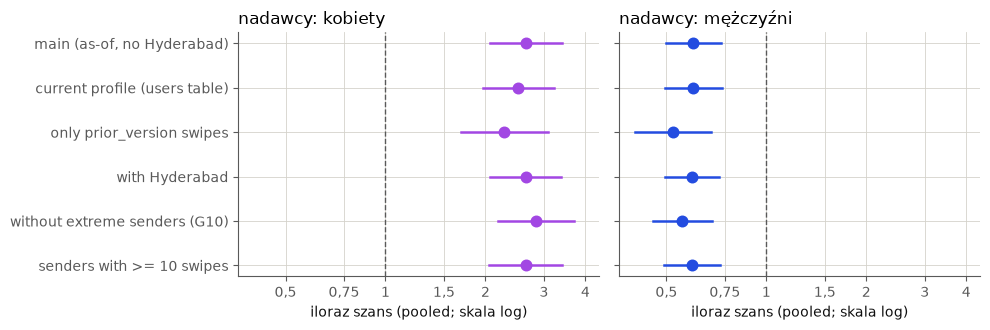

In [15]:
sens = R["sensitivity"]
sens_shown = sens[
    ["scenario", "sender_sex", "scenario_swipes", "n", "odds_ratio", "ci_low", "ci_high"]
].copy()
sens_shown.columns = [
    "wariant",
    "płeć nadawcy",
    "swipe'y w wariancie",
    "swipe'y tej płci",
    "OR (pooled)",
    "OR dół 95%",
    "OR góra 95%",
]
display(sens_shown.set_index(["wariant", "płeć nadawcy"]))
h2_figs._apply()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True)
for ax, g in zip(axes, ["F", "M"], strict=True):
    part = sens[sens["sender_sex"] == g].reset_index(drop=True)
    for y, (_, r) in enumerate(part.iterrows()):
        h2_figs._dot(ax, y, r["odds_ratio"], r["ci_low"], r["ci_high"], colors[g])
    ax.set_yticks(range(len(part)), part["scenario"] if g == "F" else [])
    ax.invert_yaxis()
    h2_figs._or_axis(ax, 0.4, 4)
    ax.set_title(f"nadawcy: {SEX_PL[g]}", loc="left")
    ax.set_xlabel("iloraz szans (pooled; skala log)")
plt.tight_layout()
plt.show()

### 6.3 Czy cechy demograficzne pomagają przewidywać swipe'y u nowych osób? (Z4)

**Jak sprawdzamy:** dzielimy ludzi na 5 grup. Uczymy model na 4, testujemy na piątej, 5 razy.
Robimy to **dwa razy**: z grupami po **nadawcach** (nowy nadawca) i po **odbiorcach** (nowy odbiorca).
Modele: `null` (stały odsetek), `sex` (para płci), `sex+age` (dodatkowo `age_band_diff`, `same_band`,
jak przed audytem), `sex+age3` (jak w H1: dodatkowo `age_band_diff_abs`).

**Jak czytać:** zbiorcze metryki out-of-fold i **sparowane różnice** z przedziałem z bootstrapu po
nadawcach (ten sam resampling dla obu modeli). `log loss`: mniejszy = lepiej. `AUC` 0,5 = zgadywanie.
`AUC-PR` porównujemy z odsetkiem prawych (null). Rozrzut między foldami pokazujemy osobno.

== foldy po nadawcach (n = 93717, bootstrap 1000) ==


metric,auc,auc_pr,logloss
block,,,
null,0.5000 [0.5000; 0.5000],0.2062 [0.1839; 0.2306],0.5089 [0.4788; 0.5417]
sex,0.5941 [0.5649; 0.6239],0.2527 [0.2214; 0.2909],0.4946 [0.4651; 0.5263]
sex+age,0.6195 [0.5900; 0.6492],0.2753 [0.2406; 0.3189],0.4912 [0.4613; 0.5228]
sex+age3,0.6288 [0.5968; 0.6587],0.2858 [0.2485; 0.3304],0.4901 [0.4603; 0.5209]


metric,auc,auc_pr,logloss
comparison,,,
sex vs null,+0.0941 [+0.0649; +0.1239],+0.0465 [+0.0286; +0.0689],-0.0143 [-0.0221; -0.0065]
sex+age vs sex,+0.0254 [+0.0118; +0.0410],+0.0226 [+0.0117; +0.0371],-0.0034 [-0.0066; -0.0003]
sex+age3 vs null,+0.1288 [+0.0968; +0.1587],+0.0796 [+0.0541; +0.1098],-0.0188 [-0.0284; -0.0086]
sex+age3 vs sex,+0.0347 [+0.0175; +0.0525],+0.0331 [+0.0202; +0.0475],-0.0045 [-0.0078; -0.0010]


logloss         auc       auc_pr      
            mean   std  mean   std   mean   std
block                                          
null       0.506 0.051 0.500 0.000  0.204 0.038
sex        0.492 0.041 0.603 0.038  0.259 0.065
sex+age    0.489 0.038 0.620 0.038  0.281 0.067
sex+age3   0.488 0.038 0.630 0.046  0.296 0.077

== foldy po odbiorcach (n = 93717, bootstrap 1000) ==


metric,auc,auc_pr,logloss
block,,,
null,0.5000 [0.5000; 0.5000],0.2062 [0.1839; 0.2306],0.5089 [0.4788; 0.5417]
sex,0.6128 [0.5880; 0.6401],0.2712 [0.2349; 0.3105],0.4914 [0.4623; 0.5224]
sex+age,0.6382 [0.6072; 0.6705],0.3031 [0.2588; 0.3582],0.4870 [0.4581; 0.5175]
sex+age3,0.6420 [0.6104; 0.6734],0.3126 [0.2648; 0.3657],0.4856 [0.4573; 0.5155]


metric,auc,auc_pr,logloss
comparison,,,
sex vs null,+0.1128 [+0.0880; +0.1401],+0.0650 [+0.0438; +0.0919],-0.0175 [-0.0259; -0.0097]
sex+age vs sex,+0.0254 [+0.0123; +0.0380],+0.0319 [+0.0145; +0.0545],-0.0044 [-0.0078; -0.0012]
sex+age3 vs null,+0.1420 [+0.1104; +0.1734],+0.1064 [+0.0725; +0.1464],-0.0233 [-0.0340; -0.0143]
sex+age3 vs sex,+0.0292 [+0.0162; +0.0418],+0.0414 [+0.0227; +0.0618],-0.0058 [-0.0090; -0.0025]


logloss         auc       auc_pr      
            mean   std  mean   std   mean   std
block                                          
null       0.509 0.007 0.500 0.000  0.206 0.005
sex        0.491 0.007 0.615 0.002  0.266 0.006
sex+age    0.487 0.007 0.639 0.005  0.300 0.006
sex+age3   0.485 0.006 0.643 0.005  0.308 0.008

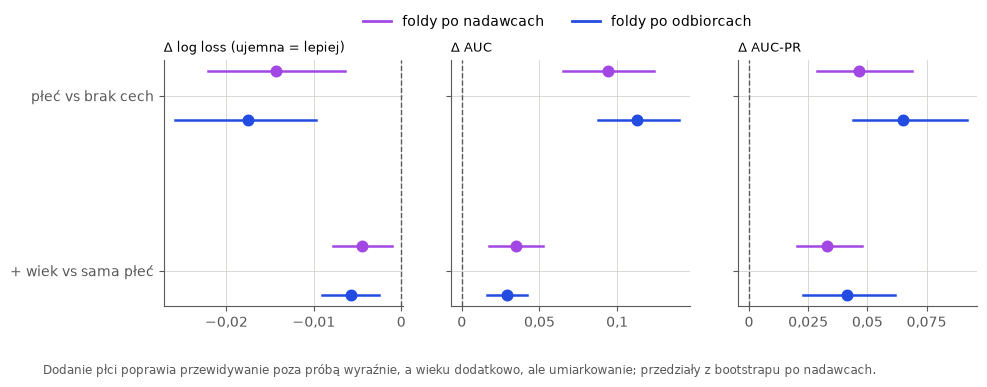

In [16]:
for g, title in (("sender", "foldy po nadawcach"), ("receiver", "foldy po odbiorcach")):
    cv = R[f"z4_cv_{g}"]
    print(f"== {title} (n = {cv['n']}, bootstrap {cv['n_boot']}) ==")
    mt = cv["metrics"].copy()
    mt["wartość [95% CI]"] = mt.apply(
        lambda r: f"{r['value']:.4f} [{r['ci_low']:.4f}; {r['ci_high']:.4f}]", axis=1
    )
    display(
        mt.pivot(index="block", columns="metric", values="wartość [95% CI]").loc[
            ["null", "sex", "sex+age", "sex+age3"]
        ]
    )
    de = cv["deltas"].copy()
    de["Δ [95% CI]"] = de.apply(
        lambda r: f"{r['delta']:+.4f} [{r['ci_low']:+.4f}; {r['ci_high']:+.4f}]", axis=1
    )
    display(de.pivot(index="comparison", columns="metric", values="Δ [95% CI]"))
    pf = cv["per_fold"]
    display(
        pf.groupby("block")[["logloss", "auc", "auc_pr"]]
        .agg(["mean", "std"])
        .loc[["null", "sex", "sex+age", "sex+age3"]]
    )
fig = h2_figs.cv_deltas(R)
plt.show()

In [17]:
# Liczby do wniosku (sekcja 7): wszystko z cache, CI 95%
def ci(r, nd=2):
    return f"{r['or']:.{nd}f} [{r['or_lo']:.{nd}f}; {r['or_hi']:.{nd}f}]"


rows = []
mx = R["z1_matrix"].set_index(["sender_sex", "receiver_sex"])
for a, b in (("F", "F"), ("F", "M"), ("M", "F"), ("M", "M")):
    r = mx.loc[(a, b)]
    rows.append(
        {
            "wniosek": f"P(prawy) {a}->{b}",
            "estymator": "bootstrap po nadawcach",
            "wartość [95% CI]": f"{r['rate']:.1%} [{r['ci_low']:.1%}; {r['ci_high']:.1%}]",
        }
    )
rows.append(
    {
        "wniosek": "różnica F->F minus F->M (p.p.)",
        "estymator": "z macierzy",
        "wartość [95% CI]": f"{100 * (mx.loc[('F', 'F'), 'rate'] - mx.loc[('F', 'M'), 'rate']):.1f}",  # noqa: E501
    }
)
rows.append(
    {
        "wniosek": "różnica M->F minus M->M (p.p.)",
        "estymator": "z macierzy",
        "wartość [95% CI]": f"{100 * (mx.loc[('M', 'F'), 'rate'] - mx.loc[('M', 'M'), 'rate']):.1f}",  # noqa: E501
    }
)
for _, r in R["or_crude"].iterrows():
    rows.append(
        {
            "wniosek": f"OR ta sama vs inna płeć, nadawcy {r['sender_sex']}, surowy",
            "estymator": "pooled",
            "wartość [95% CI]": f"{r['odds_ratio']:.3f} [{r['ci_low']:.3f}; {r['ci_high']:.3f}]",
        }
    )
for _, r in R["or_adjusted"].iterrows():
    rows.append(
        {
            "wniosek": f"OR ta sama vs inna płeć, nadawcy {r['sender_sex']}, z kontrolami",
            "estymator": "pooled",
            "wartość [95% CI]": f"{r['odds_ratio']:.3f} [{r['ci_low']:.3f}; {r['ci_high']:.3f}]",
        }
    )
for tag, lab in (("bare", "bez kontroli"), ("controls", "z kontrolami")):
    d = R[f"z1_derived_{tag}"]
    src = R[f"z1_fit_{tag}"]["pm"].get("glmm_source")
    for _, r in d.iterrows():
        if r["quantity"].split(":")[0] in ("pi", "h", "gap_F", "gap_M") or r["quantity"].startswith(
            "ratio"
        ):
            est = r["estimator"] if not r["estimator"].startswith("GLMM") else f"GLMM ({src})"
            rows.append(
                {
                    "wniosek": f"Z1 {lab}: {r['quantity']}",
                    "estymator": est,
                    "wartość [95% CI]": ci(r),
                }
            )
for key in ("dir|fe=1", "dir|fe=0", "linear|fe=1"):
    t = h2_audit.term_table(z2[key], key)
    for term in ("older_per_band", "younger_per_band", "same_band"):
        for _, r in t[t["term"] == term].iterrows():
            rows.append(
                {
                    "wniosek": f"Z2 {key}: {term}",
                    "estymator": r["estimator"] + f" ({z2[key].get('glmm_source')})"
                    if r["estimator"].startswith("GLMM")
                    else r["estimator"],
                    "wartość [95% CI]": ci(r),
                }
            )
if "z2_bridge" in R:
    for _, r in R["z2_bridge"].iterrows():
        rows.append(
            {
                "wniosek": f"most do H1, {r['step']}: {r['term']}",
                "estymator": "pooled",
                "wartość [95% CI]": ci(r),
            }
        )
for g in ("sender", "receiver"):
    cv = R[f"z4_cv_{g}"]
    for _, r in cv["metrics"].iterrows():
        if r["block"] in ("sex", "sex+age3", "null"):
            rows.append(
                {
                    "wniosek": f"CV po {g}: {r['block']} {r['metric']}",
                    "estymator": "OOF zbiorczo",
                    "wartość [95% CI]": f"{r['value']:.4f} [{r['ci_low']:.4f}; {r['ci_high']:.4f}]",
                }
            )
    for _, r in cv["deltas"].iterrows():
        if r["comparison"] == "sex+age3 vs sex":
            rows.append(
                {
                    "wniosek": f"CV po {g}: Δ {r['comparison']} {r['metric']}",
                    "estymator": "bootstrap po nadawcach",
                    "wartość [95% CI]": f"{r['delta']:+.4f} [{r['ci_low']:+.4f}; {r['ci_high']:+.4f}]",  # noqa: E501
                }
            )
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_rows", 300)
display(pd.DataFrame(rows).set_index("wniosek"))

,estymator,wartość [95% CI]
wniosek,,
P(prawy) F->F,bootstrap po nadawcach,20.0% [17.4%; 23.0%]
P(prawy) F->M,bootstrap po nadawcach,8.5% [6.2%; 11.1%]
P(prawy) M->F,bootstrap po nadawcach,29.6% [24.8%; 34.5%]
P(prawy) M->M,bootstrap po nadawcach,19.9% [16.2%; 24.0%]
różnica F->F minus F->M (p.p.),z macierzy,11.5
różnica M->F minus M->M (p.p.),z macierzy,9.7
"OR ta sama vs inna płeć, nadawcy F, surowy",pooled,2.645 [2.063; 3.390]
"OR ta sama vs inna płeć, nadawcy M, surowy",pooled,0.602 [0.498; 0.729]
"OR ta sama vs inna płeć, nadawcy O, surowy",pooled,1.074 [0.490; 2.355]


## 7. Wniosek

### Wniosek (eksploracyjny)

**Prawy swipe przewidują głównie para płci i wiek odbiorcy względem nadawcy; ocena jest warunkowa na ekspozycji.**
Opisujemy zachowanie w aplikacji wśród profili, które feed pokazał (G1), czyli korelacje, nie preferencje
ani przyczyny. Liczby poniżej są w komórce „Liczby do wniosku" wyżej; przy każdym OR podany jest
estymator: **pooled** = populacyjny („przeciętna para"), **GLMM** = warunkowy („ta sama para nadawca-odbiorca";
błędy standardowe z `lme4`, a gdy GPBoost je zwrócił, jak w Z1 z kontrolami, z GPBoost; źródło jest w tabeli). OR z różnych estymatorów **nie są porównywalne**: GLMM jest dalej od 1, bo
nadawcy bardzo różnią się chęcią swipe'owania (wariancja efektu nadawcy 7,5).

#### Płeć: co widać

| Nadawca → odbiorca | P(prawy) [95% CI, bootstrap po nadawcach] |
|---|---|
| kobiety → kobiety | 20,0% [17,4; 23,0] |
| kobiety → mężczyźni | 8,5% [6,2; 11,1] |
| mężczyźni → kobiety | 29,6% [24,8; 34,5] |
| mężczyźni → mężczyźni | 19,9% [16,2; 24,0] |

- **Profile kobiet dostają więcej prawych swipe'ów od obu grup nadawców.** Kobiety swipe'ują w prawo
  kobiety o 11,5 p.p. częściej niż mężczyzn (OR pooled 2,65 [2,06; 3,39]); mężczyźni kobiety o 9,7 p.p. częściej
  niż mężczyzn (OR „ta sama vs inna płeć" 0,60 [0,50; 0,73], pooled). Po kontroli wieku i miasta: 2,44 [1,91; 3,12]
  i 0,66 [0,54; 0,80] (pooled).
- **Da się to częściowo rozdzielić, ale tylko przy założeniu.** W tabeli 2×2 identyfikowany jest **jeden**
  kontrast: iloraz luk „odbiorca F vs M" u kobiet i u mężczyzn, `exp(2h)` = 1,59 [1,16; 2,18] (pooled; GLMM
  1,93 [1,73; 2,16]). Znaczy to, że luka jest u kobiet wyraźnie większa niż u mężczyzn, **bez** żadnych założeń.
  Jeśli dodatkowo przyjmiemy, że popularność profili kobiet i premia za własną płeć są takie same dla obu
  płci nadawców, to: popularność profili kobiet `π`: OR 2,13 [1,81; 2,51] (pooled; GLMM 3,91 [3,47; 4,39]),
  premia za własną płeć `h`: OR 1,26 [1,08; 1,48] (pooled; GLMM 1,39 [1,32; 1,47]). Wstępny rachunek
  (0,76 logitu i 0,22) potwierdził się modelem. **Większość różnicy to więc ogólnie większa liczba prawych
  swipe'ów dla profili kobiet, a premia za własną płeć jest mniejsza** (w skali logitu ok. 3 razy). Osobnych premii
  dla kobiet i mężczyzn (`h_F`, `h_M`) z tych danych nie umiemy wyznaczyć. „Popularność profili kobiet"
  to nazwa zbiorcza: `receiver_F` jest skorelowane z innymi cechami odbiorcy.
- **Z kontrolami wieku i miasta wynik jest podobny:** `π` 1,91 [1,63; 2,25], `h` 1,25 [1,07; 1,47] (pooled).
- **To nie jest twarda bramka:** kobiety dały mężczyznom 8,5% prawych swipe'ów, nie zero.
- **Płeć `O`:** poza modelem (G16). W macierzy komórki są małe i niestabilne, wniosku nie ma.

#### Wiek: kara za starszego odbiorcę, nie preferencja podobnego wieku

- Nadawcy 18–20: odsetek prawych maleje z 20,5% (to samo pasmo) przez 13,7% i 9,5% do 6,6% (odbiorcy 27+).
  Nadawcy 27+ swipe'ują podobnie we wszystkich pasmach (21,5–25,3%, przedziały szerokie).
- **OR starszego odbiorcy na jedno pasmo różnicy:** pooled z efektami stałymi pasma nadawcy 0,69 [0,61; 0,77]
  (bez nich 0,58 [0,47; 0,72]); GLMM 0,49 [0,44; 0,53]. **Młodszy odbiorca:** pooled 0,96 [0,86; 1,07],
  GLMM 0,92 [0,84; 1,01], czyli brak wyraźnej kary. **To samo pasmo:** pooled 1,03 [0,90; 1,17], GLMM 1,00
  [0,89; 1,11], czyli brak premii za zgodność pasma.
- **Spójność z H1:** starszy o 1 pasmo OR 0,62 [0,57; 0,68] (próba H1), 0,62 [0,57; 0,68] (próba H2,
  93 717), 0,62 [0,55; 0,70] (+ klastry po odbiorcach), **0,67 [0,60; 0,74]** (+ kontrole płci i miasta, pooled);
  starszy o 2+ pasma 0,36 → 0,35 → 0,35 → **0,41 [0,33; 0,50]**; młodszy o 1: 0,97 → 0,97 → 0,97 → 0,92 [0,82; 1,04].
  Różnica względem H1 wynika prawie wyłącznie z kontroli (para płci jest skorelowana z wiekiem), nie z próby
  ani z klastrowania.

#### Poza próbą (nowy nadawca / nowy odbiorca)

- AUC (zbiorczo, CI po nadawcach): sama płeć 0,59 [0,56; 0,62] (nowy odbiorca 0,61 [0,59; 0,64]),
  płeć + wiek 0,63 [0,60; 0,66] (nowy odbiorca 0,64 [0,61; 0,67]); AUC-PR płeć + wiek 0,29 [0,25; 0,33] przy
  odsetku bazowym 0,21.
- **Wiek dodaje do płci mało, ale mierzalnie** (sparowane różnice, nowy nadawca): Δ log loss −0,0045
  [−0,0078; −0,0010], Δ AUC +0,035 [0,018; 0,053], Δ AUC-PR +0,033 [0,020; 0,048]; nowy odbiorca: −0,0058
  [−0,0090; −0,0025], +0,029 [0,016; 0,042], +0,041 [0,023; 0,062]. To **zmiana wobec wersji sprzed audytu**,
  która uznawała wkład wieku za mieszczący się w szumie (porównanie z rozrzutem między foldami, nie
  sparowane). Przewidywanie pozostaje umiarkowane (AUC 0,63–0,64).

### Co jest konfirmacyjne, eksploracyjne i post hoc

- **Konfirmacyjne:** nic. H2 jest eksploracyjne, bo macierz płci widzieliśmy przed sformułowaniem hipotezy (D17).
- **Pre-rejestrowane w karcie M1 (ale w części eksploracyjnej):** OR ta sama vs inna płeć według płci nadawcy,
  model z interakcją płci i `|Δ wieku|`, `Δ wieku` ze znakiem, 6 scenariuszy wrażliwości, foldy po nadawcach.
- **Post hoc (audyt):** dekompozycja `π`/`h` z założeniem identyfikacyjnym, GLMM (`lme4`), efekty stałe
  nadawcy, macierz wieku, efekty stałe pasma, porównanie z H1, AUC-PR, foldy po odbiorcach, bootstrap różnic,
  blok `sex+age3`, stały predyktor w modelu null.

### Ograniczenia

- **Ekspozycja (G1):** widzimy tylko pary, które feed pokazał; filtry i ranking mogą zawężać zmienność płci i wieku.
- **Korelacja, nie preferencja:** „popularność profili kobiet" i „premia za własną płeć" to etykiety przy założeniu symetrii.
- **GLMM ma za wąskie przedziały dla efektów zależnych od nadawcy** (brak losowych nachyleń; np. `h`: GLMM
  [1,32; 1,47] vs pooled [1,08; 1,48]). Dla wniosków o `h` ufamy szerszemu przedziałowi pooled.
- **Płeć `O`** jest mała i często powstaje przez zmianę płci (G8, G16); wiek znamy tylko jako pasmo i dominuje 18–20 (G13); próba jest wąska (G6).
- **As-of (D7):** ok. połowa swipe'ów ma cechy z pierwszej wersji profilu (nie da się rozstrzygnąć, czy przed zmianą); wpływu nie oszacowaliśmy ilościowo (zob. `docs/h2/open-questions.md`).
- Prawy swipe to nie decyzja o wspólnym wynajmie (G9). Mamy tylko dzień, bez godzin (G3).

In [18]:
# Zapis wykresów (tylko z cache): reports/h2/figures/*.png
paths = h2_figs.save_all(R, "../reports/h2/figures")
print([p.name for p in paths])

['sex_matrix.png', 'sex_decomp_bare.png', 'sex_decomp_controls.png', 'age_matrix.png', 'age_or.png', 'estimators.png', 'cv_deltas.png', 'bridge.png']
